# DINOv2-reg en EuroSAT: *stem* nativo a 64 px como modificación del núcleo


# Modelos usados

**Modelo base:** `dinov2_vits14_reg` (ViT-S/14 con 4 *registers*, Meta).


**Referencia:** ResNet-18 desde cero.

# Problemàtica

uroSAT trae imágenes de 64×64 px (10 m/píxel). Para usar DINOv2 hay que ampliar el tamaño a 224 px por medio de la interpolaciòn y luego cortarlas en parches de 14×14. Es decir, cada token se calcula a partir de píxeles inventados
por la interpolación, con un filtro de entrada (`patch_embed`) aprendido sobre fotos web, no sobre imágenes satelitales.


# Propuesta

Reemplazamos `patch_embed` (Conv 14×14, stride 14) por un *stem* convolucional que lee directamente los
64×64 px nativos y produce la  grilla de 16×16 tokens de 384 dimensiones. Los 12 bloques Transformer quedan congelados.
Se entrena en dos etapas:
- **Etapa A (sin etiquetas):** el nuevo *stem* aprende a imitar los tokens del `patch_embed` original (destilación).
- **Etapa B (con etiquetas):** se ajustan el *stem* y la cabeza con 10 % o 100 % de etiquetas, propagando el gradiente por los bloques congelados.



# Hipòtesis

- **H1:** Con 10 % de etiquetas, DINOv2-reg congelado supera a la ResNet-18 desde cero; con 100 % la brecha se reduce.
- **H2:** El *stem* nativo (A+B) supera al `patch_embed` original con 100 % de etiquetas, porque adapta el filtro de entrada al dominio satelital.
- **H3:** Sin la etapa A (*stem* aleatorio), el modelo cae mucho con 10 % de etiquetas (sobreajuste): la destilación es lo que lo protege.
- **H4 (Fase C):** El *stem* especializado en 10 m/píxel generaliza **peor** a RESISC45 (resolución variable) que el `patch_embed` original: especializar tiene un costo.


In [7]:
!pip -q install fvcore torchinfo datasets scikit-learn

In [8]:
import os, json, time, random, warnings, hashlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision, torchvision.transforms as T
import torchvision.transforms.functional as TF
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEVICE == "cuda"  # Hace parte de los cálculos en 16 bits en lugar de 32 por lo que es más rápido y usa menos memoria
ROOT = Path("/content/data") if Path("/content").exists() else Path("./data")
FEATS, RES, FIGS = ROOT / "features", ROOT / "results", ROOT / "figures"
for p in (FEATS, RES, FIGS): p.mkdir(parents=True, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

SEED, SEEDS, BUDGETS = 42, [0, 1, 2], [0.10, 1.00]
ABLATION_SEEDS = [0]              # Cada entrenamiento del stem es el paso más caro del notebook , es por ello que solo corre la primera vez
MODEL_NAME = "dinov2_vits14_reg"
RES_IN, NATIVE = 224, 64          # entrada del modelo, entrada de eurosat
N_REG = 4                         # Se usa para saber que los primeros 5 tokens (1 CLS + 4 registers) no son parches, y excluirlos al calcular los mapas de atención.
set_seed(SEED)
print(DEVICE, torch.__version__, torch.cuda.get_device_name(0) if AMP else "")

cuda 2.11.0+cu130 Tesla T4


## 1. Datos: EuroSAT RGB
`torchvision.datasets.EuroSAT` descarga la versión RGB oficial de Helber et al. (2019): 27 000 JPG de 64×64 en 10 clases.


Fuente: https://github.com/phelber/EuroSAT (citar Helber et al., IEEE JSTARS 2019).

In [9]:
EUROSAT_CLASSES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
                   "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
euro_ds = torchvision.datasets.EuroSAT(root=str(ROOT / "data"), download=True)
assert list(euro_ds.classes) == EUROSAT_CLASSES, euro_ds.classes
euro_paths = [p for p, _ in euro_ds.samples]
euro_y = np.array([y for _, y in euro_ds.samples])
assert len(euro_paths) == 27_000, len(euro_paths)

class ImgDS(Dataset):
    def __init__(self, items, labels, tf=None): self.items, self.labels, self.tf = items, list(labels), tf
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        im = self.items[i]; im = (Image.open(im) if isinstance(im, (str, Path)) else im).convert("RGB")
        return (self.tf(im) if self.tf else im), self.labels[i]

SPLIT_FILE = ROOT / "splits.json"
if SPLIT_FILE.exists():
    SPLITS = json.loads(SPLIT_FILE.read_text())
else:
    idx = np.arange(len(euro_y))
    tr, tmp = train_test_split(idx, test_size=.30, stratify=euro_y, random_state=SEED)
    va, te = train_test_split(tmp, test_size=.50, stratify=euro_y[tmp], random_state=SEED)
    SPLITS = {"train": tr.tolist(), "val": va.tolist(), "test": te.tolist()}; SPLIT_FILE.write_text(json.dumps(SPLITS))
TR, VA, TE = (np.array(SPLITS[k]) for k in ("train", "val", "test"))

def budget(frac, seed):
    if frac >= 1: return TR
    sub, _ = train_test_split(TR, train_size=frac, stratify=euro_y[TR], random_state=seed); return np.sort(sub)
print({k: len(v) for k, v in SPLITS.items()})

{'train': 18900, 'val': 4050, 'test': 4050}


### 1.1 Ejemplos por clase y distribución

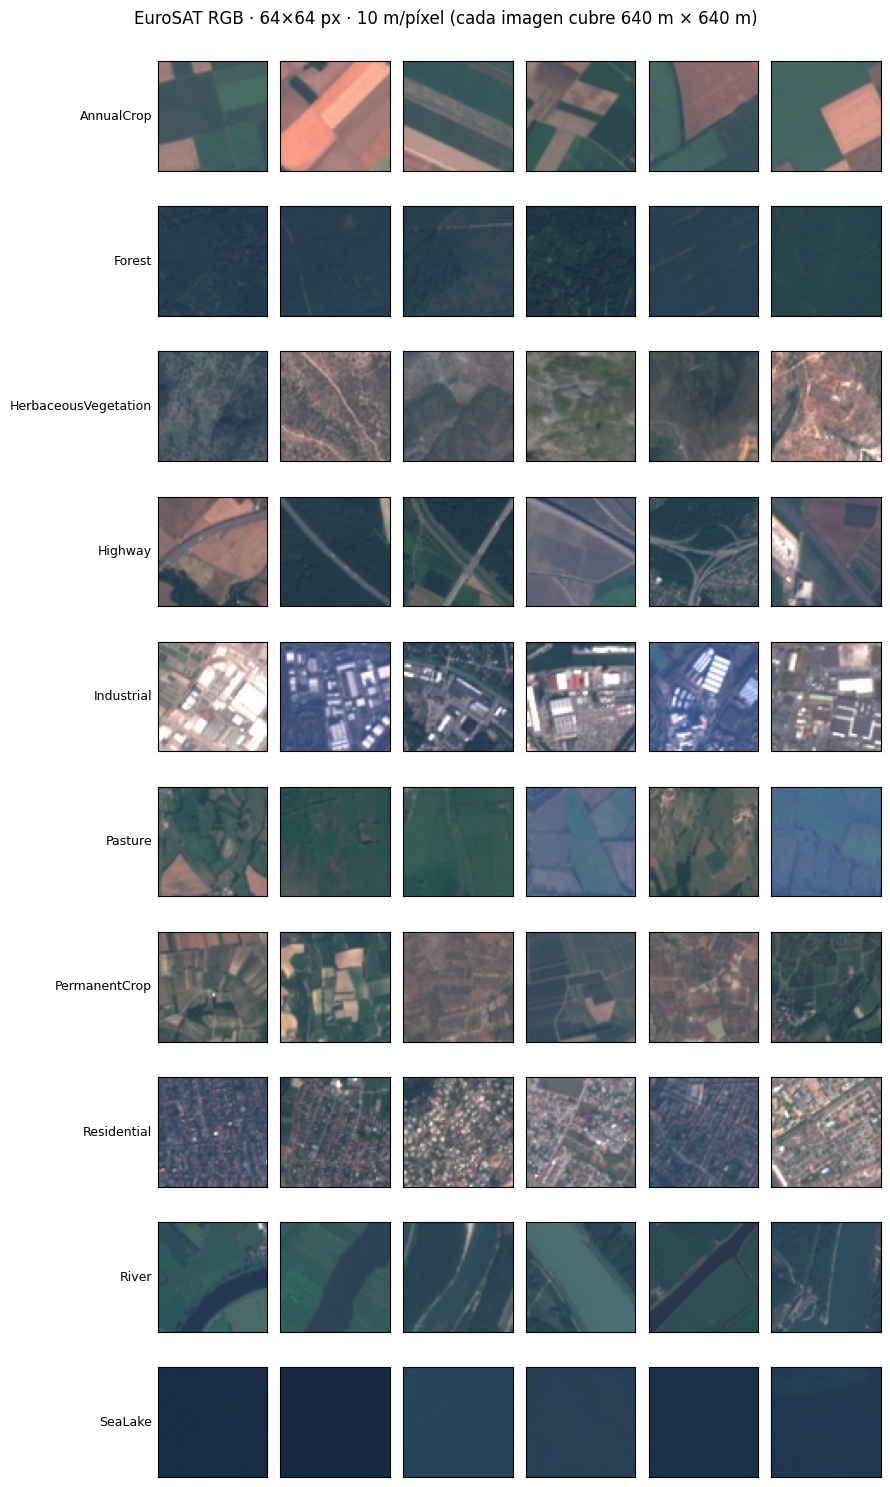

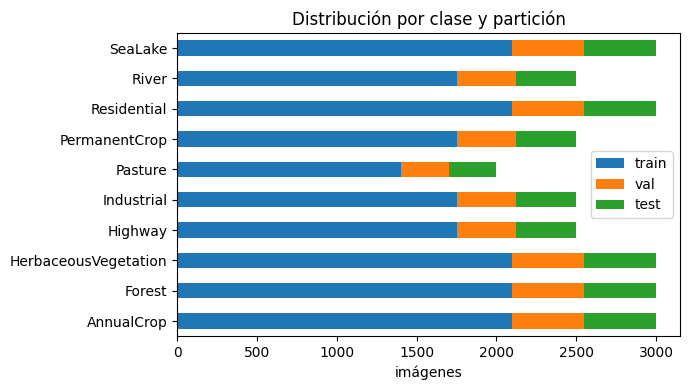

,train,val,test
AnnualCrop,2100,450,450
Forest,2100,450,450
HerbaceousVegetation,2100,450,450
Highway,1750,375,375
Industrial,1750,375,375
Pasture,1400,300,300
PermanentCrop,1750,375,375
Residential,2100,450,450
River,1750,375,375
SeaLake,2100,450,450


In [10]:
fig, ax = plt.subplots(10, 6, figsize=(9, 15))
rng = np.random.RandomState(SEED)
for c, name in enumerate(EUROSAT_CLASSES):
    for j, i in enumerate(rng.choice(np.where(euro_y == c)[0], 6, replace=False)):
        ax[c, j].imshow(Image.open(euro_paths[i])); ax[c, j].set_xticks([]); ax[c, j].set_yticks([])
    ax[c, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("EuroSAT RGB · 64×64 px · 10 m/píxel (cada imagen cubre 640 m × 640 m)", y=.995)
plt.tight_layout(); plt.savefig(FIGS / "eurosat_ejemplos.png", dpi=130); plt.show()

counts = pd.DataFrame({s: pd.Series(euro_y[ix]).value_counts().sort_index().values for s, ix in
                       [("train", TR), ("val", VA), ("test", TE)]}, index=EUROSAT_CLASSES)
counts.plot.barh(stacked=True, figsize=(7, 4)); plt.xlabel("imágenes"); plt.title("Distribución por clase y partición")
plt.tight_layout(); plt.savefig(FIGS / "eurosat_distribucion.png", dpi=130); plt.show(); display(counts)

## 2. Fase A · Teardown de DINOv2 ViT-S/14 con registers

---


### 2.1 Diagrama de la arquitectura
Con entrada de 224 px la secuencia tiene **261 tokens**: 1 CLS + 4 registers + 256 parches (16×16).

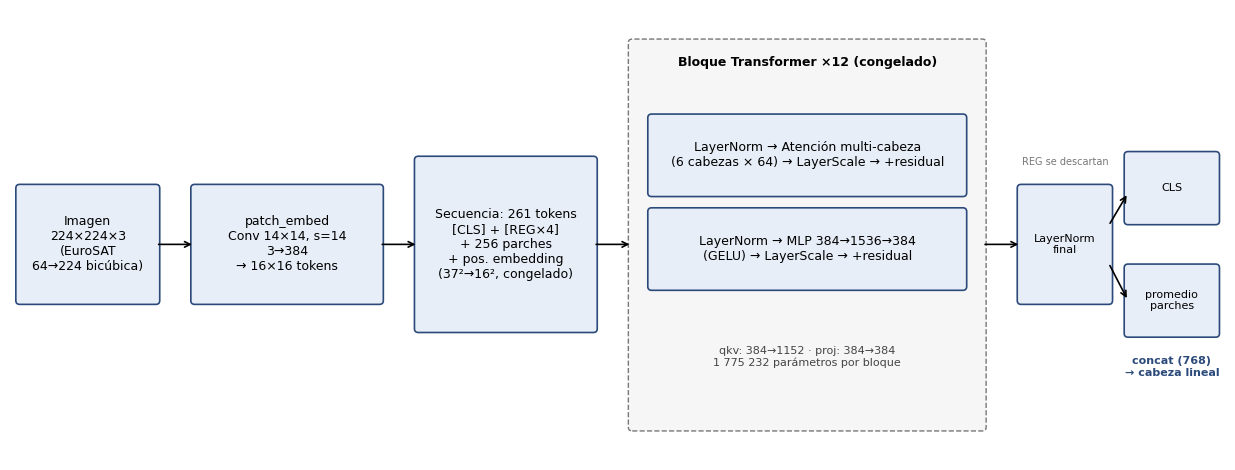

In [11]:
def draw_vit(mode="base", fname="arquitectura_dinov2_reg.png"):
    mod = mode == "stem"
    fig, ax = plt.subplots(figsize=(12.5, 4.8)); ax.set_xlim(0, 12.5); ax.set_ylim(0, 4.8); ax.axis("off")
    def box(x, y, w, h, txt, fc="#e8eef7", ec="#2b4a7a", fs=9, lw=1.2, ls="-"):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=fc, ec=ec, lw=lw, ls=ls))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs)
    def arrow(x0, y0, x1, y1): ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", lw=1.2))
    OR, ORE = "#ffd9a8", "#c25e00"
    if mod:
        box(0.1, 1.7, 1.4, 1.2, "Imagen\n64×64×3\n(nativa, sin\nampliar)", fc=OR, ec=ORE, lw=2)
        box(1.9, 1.3, 1.9, 2.0, "STEM NATIVO\nConv3×3 s1 (3→48)\nConv3×3 s2 (48→96)\nConv3×3 s2 (96→192)\nConv1×1 (192→384)\n→ 16×16 tokens",
            fc=OR, ec=ORE, lw=2.4, fs=8)
    else:
        box(0.1, 1.7, 1.4, 1.2, "Imagen\n224×224×3\n(EuroSAT\n64→224 bicúbica)")
        box(1.9, 1.7, 1.9, 1.2, "patch_embed\nConv 14×14, s=14\n3→384\n→ 16×16 tokens")
    arrow(1.5, 2.3, 1.9, 2.3)
    box(4.2, 1.4, 1.8, 1.8, "Secuencia: 261 tokens\n[CLS] + [REG×4]\n+ 256 parches\n+ pos. embedding\n(37²→16², congelado)")
    arrow(3.8, 2.3, 4.2, 2.3)
    ax.add_patch(FancyBboxPatch((6.4, 0.35), 3.6, 4.1, boxstyle="round,pad=0.04", fc="#f6f6f6", ec="#777", ls="--"))
    ax.text(8.2, 4.2, "Bloque Transformer ×12 (congelado)", ha="center", fontsize=9, weight="bold")
    box(6.6, 2.85, 3.2, 0.8, "LayerNorm → Atención multi-cabeza\n(6 cabezas × 64) → LayerScale → +residual")
    box(6.6, 1.85, 3.2, 0.8, "LayerNorm → MLP 384→1536→384\n(GELU) → LayerScale → +residual")
    ax.text(8.2, 1.0, "qkv: 384→1152 · proj: 384→384\n1 775 232 parámetros por bloque", ha="center", fontsize=8, color="#444")
    arrow(6.0, 2.3, 6.4, 2.3)
    box(10.4, 1.7, 0.9, 1.2, "LayerNorm\nfinal", fs=8); arrow(10.0, 2.3, 10.4, 2.3)
    box(11.5, 2.55, 0.9, 0.7, "CLS", fs=8); box(11.5, 1.35, 0.9, 0.7, "promedio\nparches", fs=8)
    arrow(11.3, 2.5, 11.5, 2.85); arrow(11.3, 2.1, 11.5, 1.7)
    ax.text(11.95, 0.9, "concat (768)\n→ cabeza lineal", ha="center", fontsize=8, color="#2b4a7a", weight="bold")
    ax.text(10.85, 3.15, "REG se descartan", ha="center", fontsize=7, color="#777")
    if mod:
        ax.text(0.1, 0.45, "MODIFICACIÓN: patch_embed (226 k param.,\nentrenado en fotos web) → stem entrenable\n(~283 k) que lee los 64 px reales.\nMisma salida: 16×16×384.",
                ha="left", fontsize=8.5, color=ORE, weight="bold")
    plt.tight_layout(); plt.savefig(FIGS / fname, dpi=150); plt.show()

draw_vit("base")

## Visual Transformer

Un Transformer procesa secuencias de tokens (vectores). Fue creado para texto, donde cada token es una palabra. El ViT adapta la idea a imágenes: corta la imagen en parches y trata cada parche como una “palabra”.


ViT: Vision Transformer.
S (Small): la versión pequeña, con dimensión 384 y 6 cabezas.


14: los parches miden 14×14 píxeles.


reg: tiene 4 tokens register.


## Secuencia de pasos


- **Patch embedding (patch_embed)** La imagen de 224×224 se corta en una grilla de 16×16 = 256 parches de 14×14 píxeles. Cada parche (14·14·3 = 588 números) se proyecta a un vector de 384 dimensiones. En la práctica es una convolución de 14×14 con stride 14: el filtro salta exactamente un parche cada vez, sin solaparse.

- **Tokens especiales** A los 256 parches se les añaden:

- **1 token CLS:** un vector aprendido que no viene de la imagen. Su trabajo es resumir la imagen entera, porque a lo largo de los bloques recoge información de todos los parches.
4 registers: vectores aprendidos que funcionan como “memoria de trabajo” del modelo. Total: 1 + 4 + 256 = 261 tokens.

- **Positional embedding (pos_embed)** La atención no sabe dónde está cada parche: si se barajaran, el resultado sería el mismo. Por eso a cada token se le suma un vector que codifica su posición. DINOv2 se preentrenó a 518 px, que da una grilla de 37×37, así que guarda 37² + 1 = 1 370 posiciones (la +1 es la del CLS). A 224 px, el modelo interpola esa grilla de 37×37 a 16×16.

- **12 bloques Transformer** Cada bloque tiene dos sub-bloques con la misma estructura:

x = x + LayerScale₁( Atención( LayerNorm₁(x) ) )
x = x + LayerScale₂( MLP( LayerNorm₂(x) ) )
LayerNorm: normaliza cada token (media 0, varianza 1) y luego aplica una escala γ y un desplazamiento β aprendidos. Estabiliza el entrenamiento.
Atención multi-cabeza (Multi-Head Self-Attention): es donde los tokens se comunican entre sí:
Cada token genera tres vectores: Query (qué busco), Key (qué ofrezco) y Value (qué información llevo). La capa qkv los calcula todos a la vez: 384 → 3·384 = 1152.
Se dividen en 6 cabezas de 64 dimensiones. Cada cabeza puede especializarse: unas miran vecinos cercanos, otras la imagen completa.
Cada cabeza calcula cuánto debe “atender” cada token a cada otro:
Atención = softmax(QKᵀ / √64) · V
QKᵀ es una matriz de 261×261: cada token contra todos los demás. Por eso el costo crece con el cuadrado del número de tokens, que es lo que fvcore no contaba.
La capa proj (384 → 384) mezcla de nuevo las 6 cabezas.
MLP: procesa cada token por separado, sin comunicación entre ellos. Expande a 4× (384 → 1536), aplica GELU y vuelve a 384. Si la atención “reúne” información, el MLP la “transforma”.
GELU: una función de activación suave parecida a ReLU. En lugar de cortar en seco los valores negativos, los atenúa gradualmente. Es la estándar en Transformers.
LayerScale: multiplica la salida de cada sub-bloque por un vector aprendido que empieza con valores muy pequeños (como 10⁻⁵). Así, al inicio del entrenamiento, cada bloque casi no altera la señal y la red profunda se entrena de forma estable.
Conexión residual (el x +): suma la entrada a la salida. Permite que la información y el gradiente fluyan a través de los 12 bloques sin degradarse.

- **LayerNorm final y salida** Tras el último bloque, una normalización final. Se obtienen el CLS (384 valores), que resume la imagen;
los 256 tokens de parche (384 cada uno), que describen cada región con su contexto;
los 4 registers, que se descartan.


## Uso de los registros

 Darcet et al. descubrieron que los ViT grandes reciclan parches poco informativos (cielo, fondo, agua uniforme) como espacio de memoria para cálculos globales. Esos tokens adquieren una norma muy alta y ensucian los mapas de atención. La solución: dar al modelo 4 tokens extra dedicados a esa función, que se descartan al final. Los parches quedan “limpios” y el rendimiento en ImageNet se mantiene (80.9 % frente a 81.1 %). Esto importa en imágenes satelitales, que tienen muchas zonas uniformes.




### 2.2 Inspección del modelo: activación del MLP y parámetros verificados a mano
En DINOv2, **solo ViT-g/14** usa SwiGLU; ViT-S/B/L usan un MLP estándar con **GELU**.

In [12]:
dino = torch.hub.load("facebookresearch/dinov2", MODEL_NAME).eval().to(DEVICE)
for p in dino.parameters(): p.requires_grad_(False)

blk0 = dino.blocks[0]
print("Tipo de bloque:", type(blk0).__name__)
print("MLP del bloque 0:\n", blk0.mlp)
print("Atención del bloque 0:", type(blk0.attn).__name__, "| cabezas:", blk0.attn.num_heads)
print("Registers:", dino.num_register_tokens, "| embed_dim:", dino.embed_dim, "| patch_size:", dino.patch_size)
assert isinstance(blk0.mlp.act, nn.GELU), "Se esperaba GELU (SwiGLU solo en ViT-g)"
assert dino.num_register_tokens == N_REG

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_reg4_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 110MB/s]


Tipo de bloque: NestedTensorBlock
MLP del bloque 0:
 Mlp(
  (fc1): Linear(in_features=384, out_features=1536, bias=True)
  (act): GELU(approximate='none')
  (fc2): Linear(in_features=1536, out_features=384, bias=True)
  (drop): Dropout(p=0.0, inplace=False)
)
Atención del bloque 0: MemEffAttention | cabezas: 6
Registers: 4 | embed_dim: 384 | patch_size: 14


Verificación con fórmulas (d = 384, h = 1536):

| Componente | Fórmula | Parámetros |
|---|---|---|
| `attn.qkv` | d·3d + 3d | 443 520 |
| `attn.proj` | d·d + d | 147 840 |
| `mlp.fc1` | d·h + h | 591 360 |
| `mlp.fc2` | h·d + d | 590 208 |
| 2 × LayerNorm | 2·2d | 1 536 |
| 2 × LayerScale | 2·d | 768 |
| **Total bloque** | | **1 775 232** |



,fórmula,PyTorch,coincide
attn.qkv,443520,443520,True
attn.proj,147840,147840,True
mlp.fc1,591360,591360,True
mlp.fc2,590208,590208,True
norm1+norm2,1536,1536,True
ls1+ls2,768,768,True


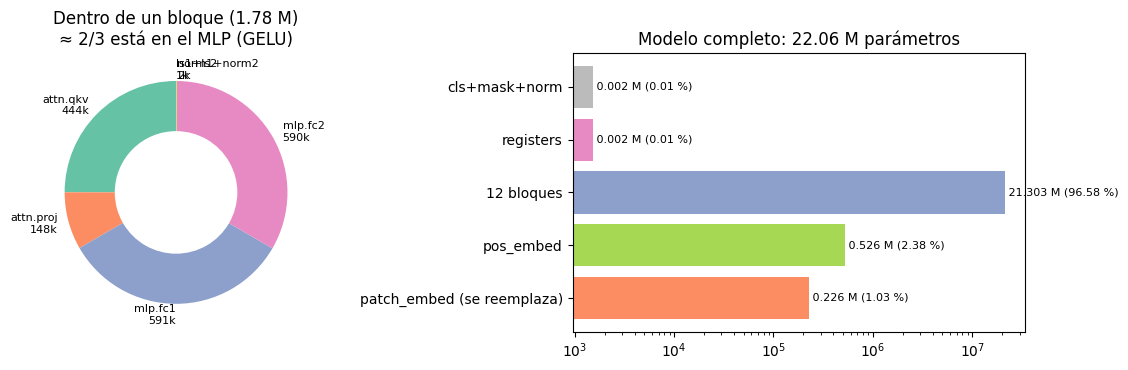

In [13]:
d, h = 384, 1536
formula = {"attn.qkv": d * 3 * d + 3 * d, "attn.proj": d * d + d, "mlp.fc1": d * h + h,
           "mlp.fc2": h * d + d, "norm1+norm2": 4 * d, "ls1+ls2": 2 * d}
count = lambda *ms: sum(p.numel() for m in ms for p in m.parameters())
real = {"attn.qkv": count(blk0.attn.qkv), "attn.proj": count(blk0.attn.proj), "mlp.fc1": count(blk0.mlp.fc1),
        "mlp.fc2": count(blk0.mlp.fc2), "norm1+norm2": count(blk0.norm1, blk0.norm2), "ls1+ls2": count(blk0.ls1, blk0.ls2)}
df_blk = pd.DataFrame({"fórmula": formula, "PyTorch": real}); df_blk["coincide"] = df_blk["fórmula"] == df_blk["PyTorch"]
display(df_blk)
assert df_blk["coincide"].all() and sum(formula.values()) == count(blk0) == 1_775_232
assert count(dino.patch_embed) == 226_176 and dino.pos_embed.shape[1] == 37 ** 2 + 1 and dino.register_tokens.numel() == 1536
total = count(dino)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].pie(list(formula.values()), labels=[f"{k}\n{v/1e3:.0f}k" for k, v in formula.items()], startangle=90,
          colors=plt.cm.Set2.colors, wedgeprops=dict(width=.45), textprops=dict(fontsize=8))
ax[0].set_title("Dentro de un bloque (1.78 M)\n≈ 2/3 está en el MLP (GELU)")
parts = {"patch_embed (se reemplaza)": 226_176, "pos_embed": 526_080, "12 bloques": 12 * 1_775_232,
         "registers": 1536, "cls+mask+norm": total - 226_176 - 526_080 - 12 * 1_775_232 - 1536}
ax[1].barh(list(parts), list(parts.values()), color=["#fc8d62", "#a6d854", "#8da0cb", "#e78ac3", "#bbbbbb"])
for i, v in enumerate(parts.values()): ax[1].text(v, i, f" {v/1e6:.3f} M ({100*v/total:.2f} %)", va="center", fontsize=8)
ax[1].set_xscale("log"); ax[1].set_title(f"Modelo completo: {total/1e6:.2f} M parámetros")
plt.tight_layout(); plt.savefig(FIGS / "teardown_parametros.png", dpi=150); plt.show()

### 2.3 FLOPs por bloque
**Paso 1.** Medimos con `fvcore` a tres resoluciones. La columna `tokens N` incluye CLS y registers (N = parches + 5).

In [14]:
from fvcore.nn import FlopCountAnalysis
rows, UNSUP = [], None
for r in [112, 224, 448]:
    fca = FlopCountAnalysis(dino, torch.randn(1, 3, r, r, device=DEVICE))
    fca.unsupported_ops_warnings(False); fca.uncalled_modules_warnings(False)
    bm = fca.by_module(); tot = fca.total()
    UNSUP = fca.unsupported_ops()
    rows.append({"resolución": r, "tokens N": (r // 14) ** 2 + 1 + N_REG,
                 "fvcore atención bloque 0 (G)": bm["blocks.0.attn"] / 1e9, "fvcore MLP bloque 0 (G)": bm["blocks.0.mlp"] / 1e9,
                 "fvcore total (G)": tot / 1e9})
df_fv = pd.DataFrame(rows).set_index("resolución")
df_fv["×tokens vs 224"] = df_fv["tokens N"] / df_fv.loc[224, "tokens N"]
df_fv["×atención vs 224"] = df_fv["fvcore atención bloque 0 (G)"] / df_fv.loc[224, "fvcore atención bloque 0 (G)"]
display(df_fv.round(4))
print("Operadores que fvcore NO contó:", dict(UNSUP))

,tokens N,fvcore atención bloque 0 (G),fvcore MLP bloque 0 (G),fvcore total (G),×tokens vs 224,×atención vs 224
resolución,,,,,,
112,69,0.0407,0.0814,1.4829,0.2644,0.2644
224,261,0.1539,0.3079,5.6123,1.0000,1.0000
448,1029,0.6069,1.2139,22.1300,3.9425,3.9425


Operadores que fvcore NO contó: {'aten::_upsample_bicubic2d_aa': 1, 'aten::add': 25, 'aten::scaled_dot_product_attention': 12, 'aten::mul': 24, 'aten::gelu': 12}


**Paso 2. Lo que se observa.** De 224 a 448 px los tokens crecen ~×4 y la columna "atención" de fvcore también crece ~×4.
Pero la atención calcula QKᵀ (una matriz N×N), así que debería crecer ~×16. Algo no se está contando.

La lista de operadores no contados lo explica: DINOv2 calcula `softmax(QKᵀ)V` con un operador fusionado
(`scaled_dot_product_attention` o xformers) que fvcore no sabe contar. Solo contó las capas lineales `qkv` y `proj`.
Además, fvcore reporta MACs (una multiplicación-suma = 1).

**Paso 3. Corrección analítica** (N = tokens, d = 384, h = 1536), validando la parte lineal contra fvcore:

| Operación | MACs por bloque |
|---|---|
| qkv | N·d·3d |
| QKᵀ y A·V | 2·N²·d ← **cuadrático, lo que falta** |
| proj | N·d·d |
| MLP | 2·N·d·h |

,fvcore atención,fórmula qkv+proj,fvcore MLP,fórmula MLP,QKᵀ+AV (no contado),total real (G)
resolución,,,,,,
112,0.0407,0.0407,0.0814,0.0814,0.0037,1.5268
224,0.1539,0.1539,0.3079,0.3079,0.0523,6.2401
448,0.6069,0.6069,1.2139,1.2139,0.8132,31.8883


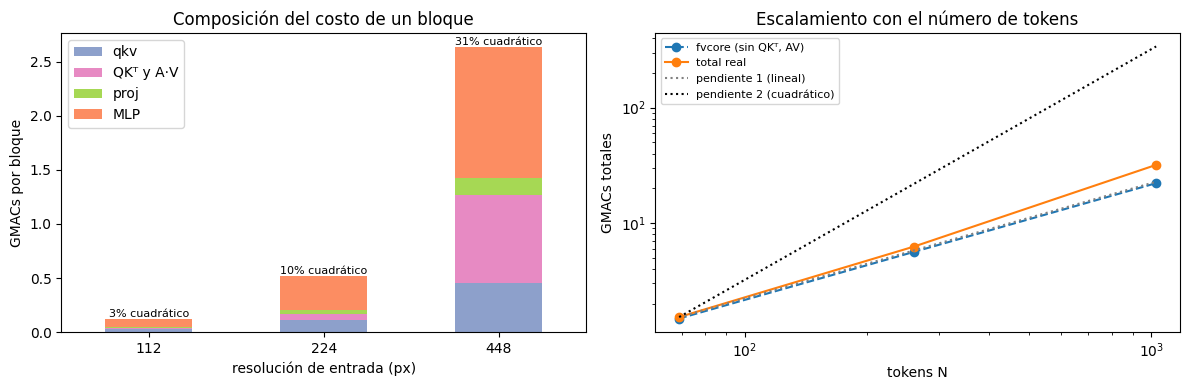

In [15]:
def analytic_macs(res, d=384, h=1536, regs=N_REG):
    N = (res // 14) ** 2 + 1 + regs
    return {"qkv": N * d * 3 * d, "QKᵀ y A·V": 2 * N * N * d, "proj": N * d * d, "MLP": 2 * N * d * h, "N": N}

chk = []
for r in [112, 224, 448]:
    a = analytic_macs(r)
    chk.append({"resolución": r, "fvcore atención": df_fv.loc[r, "fvcore atención bloque 0 (G)"],
                "fórmula qkv+proj": (a["qkv"] + a["proj"]) / 1e9, "fvcore MLP": df_fv.loc[r, "fvcore MLP bloque 0 (G)"],
                "fórmula MLP": a["MLP"] / 1e9, "QKᵀ+AV (no contado)": a["QKᵀ y A·V"] / 1e9,
                "total real (G)": df_fv.loc[r, "fvcore total (G)"] + 12 * a["QKᵀ y A·V"] / 1e9})
df_fl = pd.DataFrame(chk).set_index("resolución"); df_fl.to_csv(RES / "teardown_flops.csv"); display(df_fl.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
comp = pd.DataFrame({r: {k: v / 1e9 for k, v in analytic_macs(r).items() if k != "N"} for r in [112, 224, 448]}).T
comp.plot.bar(stacked=True, ax=ax[0], color=["#8da0cb", "#e78ac3", "#a6d854", "#fc8d62"], rot=0)
for i, r in enumerate(comp.index):
    ax[0].text(i, comp.loc[r].sum(), f"{100*comp.loc[r,'QKᵀ y A·V']/comp.loc[r].sum():.0f}% cuadrático", ha="center", va="bottom", fontsize=8)
ax[0].set_xlabel("resolución de entrada (px)"); ax[0].set_ylabel("GMACs por bloque"); ax[0].set_title("Composición del costo de un bloque")
Ns = df_fv["tokens N"].values.astype(float)
ax[1].loglog(Ns, df_fv["fvcore total (G)"], "o--", label="fvcore (sin QKᵀ, AV)")
ax[1].loglog(Ns, df_fl["total real (G)"], "o-", label="total real")
ax[1].loglog(Ns, df_fl["total real (G)"].iloc[0] * (Ns / Ns[0]), ":", c="gray", label="pendiente 1 (lineal)")
ax[1].loglog(Ns, df_fl["total real (G)"].iloc[0] * (Ns / Ns[0]) ** 2, ":", c="k", label="pendiente 2 (cuadrático)")
ax[1].set_xlabel("tokens N"); ax[1].set_ylabel("GMACs totales"); ax[1].legend(fontsize=8); ax[1].set_title("Escalamiento con el número de tokens")
plt.tight_layout(); plt.savefig(FIGS / "teardown_flops.png", dpi=150); plt.show()

### 2.4 Campo receptivo de un ViT: distancia media de atención

En un Vision Transformer la situación es distinta. Como la atención compara cada token con todos los demás, desde el primer bloque cualquier parche puede recibir información de cualquier otro.

Para cada cabeza: Σⱼ aᵢⱼ·dist(i, j) entre parches (se excluyen CLS y registers), en **metros sobre el terreno** (16 parches = 640 m).

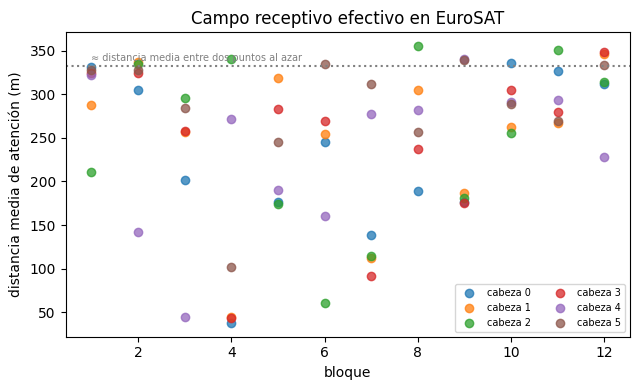

In [16]:
@torch.no_grad()
def attention_maps(model, x):
    caps = []
    def hook(mod, inp):
        z = inp[0]; B, N, C = z.shape; hh = mod.num_heads
        qkv = mod.qkv(z).reshape(B, N, 3, hh, C // hh).permute(2, 0, 3, 1, 4)
        caps.append(((qkv[0] * mod.scale) @ qkv[1].transpose(-2, -1)).softmax(-1).float().cpu())
    hs = [b.attn.register_forward_pre_hook(hook) for b in model.blocks]
    try: model(x)
    finally: [h_.remove() for h_ in hs]
    return caps

IMNET = dict(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
dino_tf = T.Compose([T.Resize((RES_IN, RES_IN), interpolation=T.InterpolationMode.BICUBIC, antialias=True), T.ToTensor(), T.Normalize(**IMNET)])
native_tf = T.Compose([T.Resize((NATIVE, NATIVE), antialias=True), T.ToTensor(), T.Normalize(**IMNET)])
G, PRE = RES_IN // 14, 1 + N_REG       # grilla 16×16 y tokens no-parche al inicio

x_val = torch.stack([ImgDS([euro_paths[i]], [0], dino_tf)[0][0] for i in VA[:128]]).to(DEVICE)
yy, xx = torch.meshgrid(torch.arange(G), torch.arange(G), indexing="ij")
dist_m = torch.cdist(*(2 * [torch.stack([yy.flatten(), xx.flatten()], 1).float()])) * 640 / G

def mean_attn_distance(maps):
    return torch.stack([(a[:, :, PRE:, PRE:] / a[:, :, PRE:, PRE:].sum(-1, keepdim=True) * dist_m).sum(-1).mean((0, 2)) for a in maps]).numpy()

mad_base = mean_attn_distance(attention_maps(dino, x_val))
plt.figure(figsize=(6.5, 4))
for hd in range(mad_base.shape[1]): plt.plot(range(1, 13), mad_base[:, hd], "o", alpha=.75, label=f"cabeza {hd}")
plt.axhline(640 * 0.52, ls=":", c="gray"); plt.text(1, 640 * 0.52 + 5, "≈ distancia media entre dos puntos al azar", fontsize=7, color="gray")
plt.xlabel("bloque"); plt.ylabel("distancia media de atención (m)"); plt.legend(fontsize=7, ncol=2); plt.title("Campo receptivo efectivo en EuroSAT")
plt.tight_layout(); plt.savefig(FIGS / "teardown_distancia_atencion.png", dpi=150); plt.show()

### 2.5 Qué "ve" el modelo: PCA de parches y atención del CLS por clase

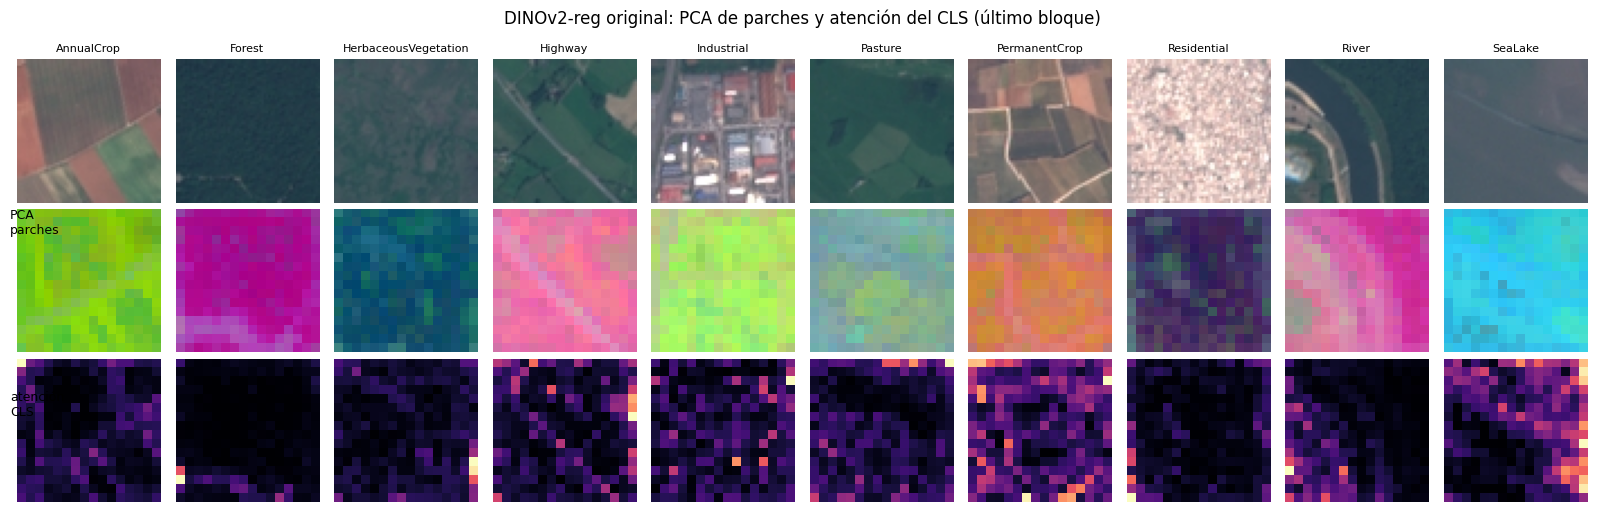

In [17]:
@torch.no_grad()
def tokens_and_attention(model, x):
    """Devuelve parches normalizados [B,256,384] y atención CLS→parches del último bloque [B,16,16]."""
    maps = attention_maps(model, x) if not hasattr(model, "stem") else model.attention_maps(x)
    pt = (model.forward_features(x)["x_norm_patchtokens"] if not hasattr(model, "stem") else model.features(x)["patch"]).float().cpu()
    att = maps[-1][:, :, 0, PRE:].mean(1).reshape(-1, G, G)
    return pt, att, maps

def pca_attention_grid(model, tf, fname, title):
    idxs = [TE[np.where(euro_y[TE] == c)[0][0]] for c in range(10)]
    x = torch.stack([ImgDS([euro_paths[i]], [0], tf)[0][0] for i in idxs]).to(DEVICE)
    pt, att, _ = tokens_and_attention(model, x)
    flat = pt.reshape(-1, pt.shape[-1]); flat = flat - flat.mean(0)
    _, _, V = torch.pca_lowrank(flat, q=3); pr = (flat @ V[:, :3]).reshape(10, G, G, 3)
    pr = (pr - pr.amin((0, 1, 2))) / (pr.amax((0, 1, 2)) - pr.amin((0, 1, 2)))
    fig, ax = plt.subplots(3, 10, figsize=(16, 5.2))
    for j, i in enumerate(idxs):
        ax[0, j].imshow(Image.open(euro_paths[i])); ax[0, j].set_title(EUROSAT_CLASSES[euro_y[i]], fontsize=8)
        ax[1, j].imshow(pr[j]); ax[2, j].imshow(att[j], cmap="magma")
        for r in range(3): ax[r, j].axis("off")
    fig.text(0.005, .55, "PCA\nparches", fontsize=9); fig.text(0.005, .2, "atención\nCLS", fontsize=9)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(FIGS / fname, dpi=140); plt.show()

pca_attention_grid(dino, dino_tf, "pca_atencion_base.png", "DINOv2-reg original: PCA de parches y atención del CLS (último bloque)")

### Modificaciones del nùcleo
**Previa**. La imagen de 64 px se amplía a 224 px y se corta en parches de 14×14 px. Cada parche corresponde a
4×4 píxeles reales (40 m × 40 m), pero el `patch_embed` ve 196 píxeles, casi todos **interpolados**.

**Modificaciòn**. El *stem* lee los 64×64 píxeles reales; cada token resume también 4×4 píxeles reales (stride total 4),
pero sin interpolación y con filtros aprendidos sobre imágenes satelitales. **El resto del modelo no cambia**: misma grilla 16×16,
mismos 261 tokens, mismos 12 bloques congelados.

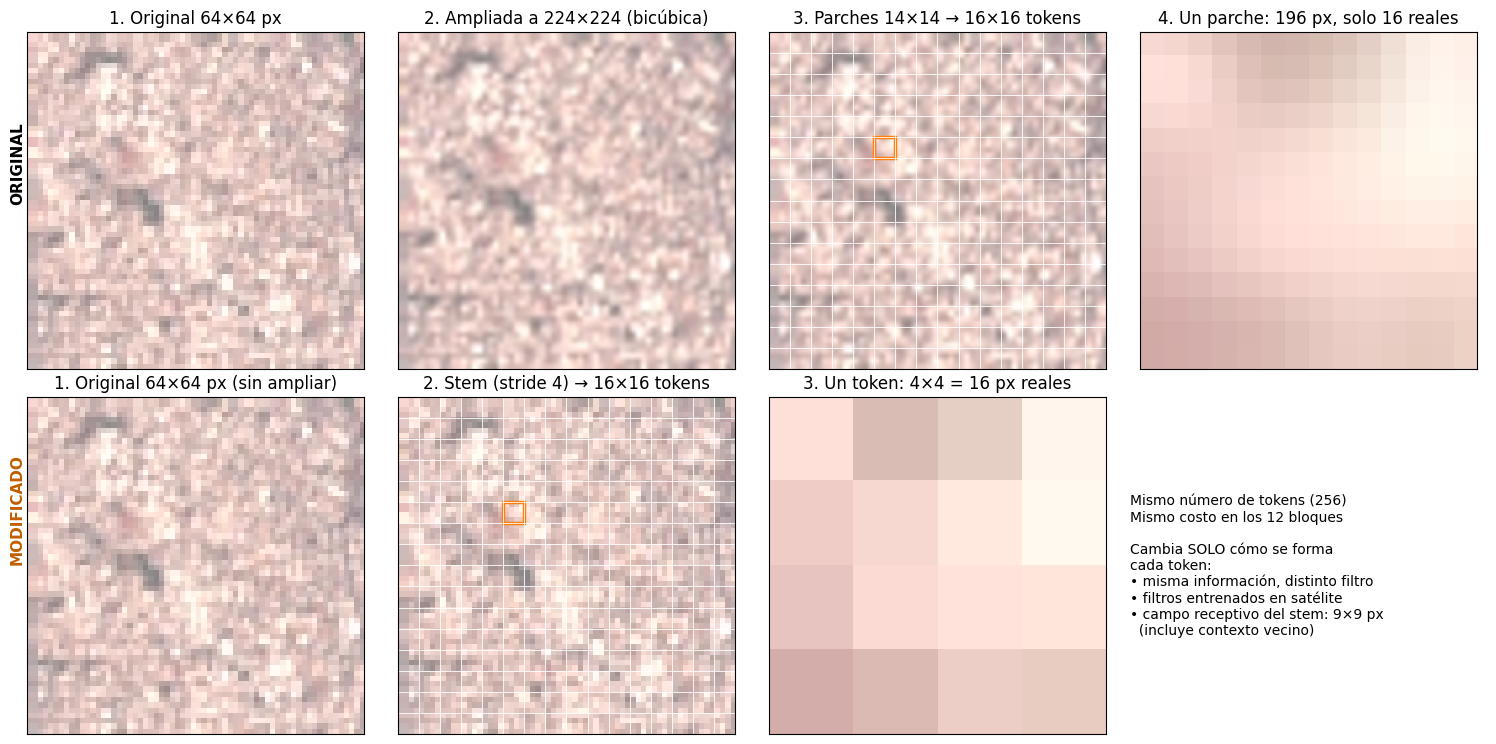

In [18]:
i0 = TE[np.where(euro_y[TE] == EUROSAT_CLASSES.index("Residential"))[0][0]]
im64 = Image.open(euro_paths[i0]).convert("RGB")
im224 = im64.resize((224, 224), Image.BICUBIC)
fig, ax = plt.subplots(2, 4, figsize=(15, 7.5))
ax[0, 0].imshow(im64); ax[0, 0].set_title("1. Original 64×64 px")
ax[0, 1].imshow(im224); ax[0, 1].set_title("2. Ampliada a 224×224 (bicúbica)")
ax[0, 2].imshow(im224)
for k in range(0, 225, 14): ax[0, 2].axhline(k - .5, c="w", lw=.6); ax[0, 2].axvline(k - .5, c="w", lw=.6)
ax[0, 2].add_patch(Rectangle((5 * 14 - .5, 5 * 14 - .5), 14, 14, fill=False, ec="#ff7f0e", lw=2.5)); ax[0, 2].set_title("3. Parches 14×14 → 16×16 tokens")
ax[0, 3].imshow(np.array(im224)[5 * 14:6 * 14, 5 * 14:6 * 14], interpolation="nearest"); ax[0, 3].set_title("4. Un parche: 196 px, solo 16 reales")
ax[1, 0].imshow(im64); ax[1, 0].set_title("1. Original 64×64 px (sin ampliar)")
ax[1, 1].imshow(im64, interpolation="nearest")
for k in range(0, 65, 4): ax[1, 1].axhline(k - .5, c="w", lw=.6); ax[1, 1].axvline(k - .5, c="w", lw=.6)
ax[1, 1].add_patch(Rectangle((5 * 4 - .5, 5 * 4 - .5), 4, 4, fill=False, ec="#ff7f0e", lw=2.5)); ax[1, 1].set_title("2. Stem (stride 4) → 16×16 tokens")
ax[1, 2].imshow(np.array(im64)[5 * 4:6 * 4, 5 * 4:6 * 4], interpolation="nearest"); ax[1, 2].set_title("3. Un token: 4×4 = 16 px reales")
ax[1, 3].axis("off"); ax[1, 3].text(0, .5, "Mismo número de tokens (256)\nMismo costo en los 12 bloques\n\nCambia SOLO cómo se forma\ncada token:\n• misma información, distinto filtro\n• filtros entrenados en satélite\n• campo receptivo del stem: 9×9 px\n  (incluye contexto vecino)",
                                    fontsize=10, va="center")
for a in ax.flatten()[:7]: a.set_xticks([]); a.set_yticks([])
fig.text(0.005, .73, "ORIGINAL", fontsize=11, weight="bold", rotation=90); fig.text(0.005, .25, "MODIFICADO", fontsize=11, weight="bold", rotation=90, color="#c25e00")
plt.tight_layout(); plt.savefig(FIGS / "que_modificamos_imagen.png", dpi=140); plt.show()

## 3. Fase B.1 · Línea base
### 3.1 DINOv2-reg congelado + cabeza lineal
**Protocolo de referencia:**
- Oquab et al., *DINOv2* (TMLR 2024), Apéndice B.3: clasificador lineal sobre CLS concatenado con el promedio de parches, backbone congelado.

- Variante con registers: Darcet et al., *Vision Transformers Need Registers* (ICLR 2024).

Como el backbone está congelado, las features se extraen una sola vez y la cabeza se entrena por épocas sobre ellas.

In [19]:
@torch.no_grad()
def extract_feats(model, items, labels, tag, tf, bs=128):
    path = FEATS / f"{tag}.pt"
    if path.exists(): return torch.load(path)
    dl = DataLoader(ImgDS(items, labels, tf), batch_size=bs, num_workers=2, pin_memory=AMP)
    F_, Y_ = [], []
    for x, y in dl:
        with torch.autocast("cuda", enabled=AMP):
            F_.append(readout(model, x.to(DEVICE)).float().cpu())
        Y_.append(torch.as_tensor(y))
    out = (torch.cat(F_), torch.cat(Y_)); torch.save(out, path); return out

def readout(model, x):
    """CLS ‖ promedio de parches (768). Los registers se descartan."""
    if hasattr(model, "stem"):
        o = model.features(x); return torch.cat([o["cls"], o["patch"].mean(1)], 1)
    o = model.forward_features(x); return torch.cat([o["x_norm_clstoken"], o["x_norm_patchtokens"].mean(1)], 1)

t0 = time.perf_counter()
Xe, Ye = extract_feats(dino, euro_paths, euro_y, "eurosat_reg_base", dino_tf)
print(f"features {tuple(Xe.shape)} en {time.perf_counter()-t0:.0f}s")

def run_epochs(model, params, dl_tr, eval_fn, epochs, lr=None, wd=1e-4, name="", eval_every=1, patience=None):
    opt = torch.optim.AdamW(params, lr=lr or 1e-3, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(dl_tr))
    scaler = torch.amp.GradScaler(enabled=AMP); hist, best, bad = [], (-1, None), 0
    for ep in range(1, epochs + 1):
        model.train(); tl, tc, tn, t0 = 0, 0, 0, time.perf_counter()
        for x, y in dl_tr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast("cuda", enabled=AMP):
                logits = model(x); loss = F.cross_entropy(logits, y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); tc += (logits.argmax(1) == y).sum().item(); tn += len(y)
        if ep % eval_every and ep != epochs: continue
        vl, va_acc, vf1 = eval_fn(model)
        hist.append({"epoch": ep, "train_loss": tl / tn, "train_acc": tc / tn, "val_loss": vl, "val_acc": va_acc, "val_f1": vf1, "seg": time.perf_counter() - t0})
        if vf1 > best[0]: best, bad = (vf1, {k: v.detach().clone() for k, v in model.state_dict().items()}), 0
        else: bad += 1
        print(f"[{name}] ep {ep:03d} | train loss {tl/tn:.3f} acc {tc/tn:.3f} | val loss {vl:.3f} acc {va_acc:.3f} f1 {vf1:.3f}")
        if patience and bad >= patience: print(f"[{name}] early stopping en época {ep}"); break
    model.load_state_dict(best[1]); return pd.DataFrame(hist)

@torch.no_grad()
def eval_loader(model, dl):
    model.eval(); L, P, Yv = 0, [], []
    for x, y in dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast("cuda", enabled=AMP): lg = model(x)
        L += F.cross_entropy(lg.float(), y, reduction="sum").item(); P.append(lg.argmax(1).cpu()); Yv.append(y.cpu())
    P, Yv = torch.cat(P).numpy(), torch.cat(Yv).numpy()
    return L / len(Yv), accuracy_score(Yv, P), f1_score(Yv, P, average="macro"), P, Yv

def feat_loader(X, Y, ix, shuffle, bs=64):
    return DataLoader(TensorDataset(X[ix], Y[ix]), batch_size=bs, shuffle=shuffle, generator=torch.Generator().manual_seed(SEED))

LP_EPOCHS, LP_LR = 25, 1e-3
RESULTS, CURVES, PREDS = [], {}, {}
def log_result(name, b, s, hist, model_eval, params):
    _, acc, f1, P, Yt = model_eval
    RESULTS.append({"modelo": name, "presupuesto": b, "semilla": s, "acc": acc, "f1": f1, "params_entrenables": params,
                    "seg_total": hist.seg.sum(), "gap_train_val": hist.train_acc.iloc[-1] - hist.val_acc.iloc[-1]})
    CURVES[(name, b, s)] = hist; PREDS[(name, b, s)] = (Yt, P)

def train_linear_head(X, Y, name, tag):
    for b in BUDGETS:
        for s in SEEDS:
            set_seed(s); head = nn.Linear(768, 10).to(DEVICE)
            dl_va, dl_te = feat_loader(X, Y, VA, False, 512), feat_loader(X, Y, TE, False, 512)
            hist = run_epochs(head, head.parameters(), feat_loader(X, Y, budget(b, s), True), lambda m: eval_loader(m, dl_va)[:3],
                              LP_EPOCHS, LP_LR, name=f"{name} {int(b*100)}% s{s}")
            log_result(name, b, s, hist, eval_loader(head, dl_te), 768 * 10 + 10)
            torch.save(head.state_dict(), RES / f"head_{tag}_b{b}_s{s}.pt")

BASE_NAME = "DINOv2-reg (original)"
train_linear_head(Xe, Ye, BASE_NAME, "base")

features (27000, 768) en 63s
[DINOv2-reg (original) 10% s0] ep 001 | train loss 1.091 acc 0.659 | val loss 0.542 acc 0.852 f1 0.846
[DINOv2-reg (original) 10% s0] ep 002 | train loss 0.382 acc 0.899 | val loss 0.366 acc 0.900 f1 0.896
[DINOv2-reg (original) 10% s0] ep 003 | train loss 0.261 acc 0.939 | val loss 0.305 acc 0.917 f1 0.913
[DINOv2-reg (original) 10% s0] ep 004 | train loss 0.206 acc 0.952 | val loss 0.271 acc 0.924 f1 0.921
[DINOv2-reg (original) 10% s0] ep 005 | train loss 0.172 acc 0.961 | val loss 0.253 acc 0.928 f1 0.925
[DINOv2-reg (original) 10% s0] ep 006 | train loss 0.145 acc 0.971 | val loss 0.234 acc 0.936 f1 0.933
[DINOv2-reg (original) 10% s0] ep 007 | train loss 0.128 acc 0.978 | val loss 0.225 acc 0.937 f1 0.935
[DINOv2-reg (original) 10% s0] ep 008 | train loss 0.115 acc 0.980 | val loss 0.216 acc 0.939 f1 0.936
[DINOv2-reg (original) 10% s0] ep 009 | train loss 0.104 acc 0.981 | val loss 0.212 acc 0.937 f1 0.934
[DINOv2-reg (original) 10% s0] ep 010 | trai

### 3.2 ResNet-18 desde cero (referencia)
- `resnet18(weights=None)`: sin preentrenamiento. Adaptada a 64×64: `conv1` 3×3 stride 1 y sin `maxpool`.
- Aumentos: flips y rotaciones de 90°. AdamW, lr 1e-3, cosine.
- 30 épocas con 100 %; con 10 % se usa el mismo **número de pasos** (≈300 épocas) para no penalizarla.

In [ ]:
class Rot90:
    def __call__(self, x): return torch.rot90(x, random.randint(0, 3), (1, 2))
_xs = torch.stack([T.ToTensor()(Image.open(euro_paths[i]).convert("RGB")) for i in TR[:3000]])
CNN_NORM = dict(mean=_xs.mean((0, 2, 3)).tolist(), std=_xs.std((0, 2, 3)).tolist())
cnn_tr_tf = T.Compose([T.Resize((64, 64), antialias=True), T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.ToTensor(), Rot90(), T.Normalize(**CNN_NORM)])
cnn_ev_tf = T.Compose([T.Resize((64, 64), antialias=True), T.ToTensor(), T.Normalize(**CNN_NORM)])

def make_resnet18(nc=10):
    m = torchvision.models.resnet18(weights=None, num_classes=nc)
    m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False); m.maxpool = nn.Identity(); return m

def img_loader(ix, tf, shuffle, bs=128, items=None, labels=None):
    items = items if items is not None else [euro_paths[i] for i in ix]
    labels = labels if labels is not None else euro_y[ix]
    return DataLoader(ImgDS(items, labels, tf), batch_size=bs, shuffle=shuffle, num_workers=2, pin_memory=AMP,
                      drop_last=shuffle and len(labels) > bs, generator=torch.Generator().manual_seed(SEED))

CNN_NAME, CNN_EPOCHS_FULL = "ResNet-18 (desde cero)", 30
dl_va_c, dl_te_c = img_loader(VA, cnn_ev_tf, False, 256), img_loader(TE, cnn_ev_tf, False, 256)
CNNS = {}
for b in BUDGETS:
    for s in SEEDS:
        set_seed(s); cnn = make_resnet18().to(DEVICE); ep = int(round(CNN_EPOCHS_FULL / b))
        hist = run_epochs(cnn, cnn.parameters(), img_loader(budget(b, s), cnn_tr_tf, True), lambda m: eval_loader(m, dl_va_c)[:3],
                          ep, 1e-3, wd=5e-4, name=f"ResNet-18 {int(b*100)}% s{s}", eval_every=max(1, ep // 30))
        log_result(CNN_NAME, b, s, hist, eval_loader(cnn, dl_te_c), count(cnn))
        torch.save(cnn.state_dict(), RES / f"resnet18_b{b}_s{s}.pt"); CNNS[(b, s)] = cnn

[ResNet-18 10% s0] ep 010 | train loss 0.653 acc 0.757 | val loss 0.701 acc 0.759 f1 0.750
[ResNet-18 10% s0] ep 020 | train loss 0.440 acc 0.846 | val loss 0.656 acc 0.774 f1 0.767
[ResNet-18 10% s0] ep 030 | train loss 0.292 acc 0.899 | val loss 0.881 acc 0.759 f1 0.754
[ResNet-18 10% s0] ep 040 | train loss 0.267 acc 0.907 | val loss 0.382 acc 0.879 f1 0.875
[ResNet-18 10% s0] ep 050 | train loss 0.197 acc 0.928 | val loss 1.066 acc 0.753 f1 0.749
[ResNet-18 10% s0] ep 060 | train loss 0.227 acc 0.924 | val loss 0.586 acc 0.836 f1 0.830
[ResNet-18 10% s0] ep 070 | train loss 0.146 acc 0.953 | val loss 0.416 acc 0.888 f1 0.886
[ResNet-18 10% s0] ep 080 | train loss 0.110 acc 0.963 | val loss 0.333 acc 0.901 f1 0.899
[ResNet-18 10% s0] ep 090 | train loss 0.095 acc 0.963 | val loss 0.360 acc 0.891 f1 0.889
[ResNet-18 10% s0] ep 100 | train loss 0.065 acc 0.978 | val loss 0.930 acc 0.832 f1 0.828
[ResNet-18 10% s0] ep 110 | train loss 0.048 acc 0.985 | val loss 0.394 acc 0.906 f1 0.902

### 3.3 Curvas de entrenamiento y comparación de la línea base

In [ ]:
def plot_curves(models, fname, seed=SEEDS[0]):
    fig, ax = plt.subplots(len(BUDGETS), 2, figsize=(12, 3.6 * len(BUDGETS)))
    for i, b in enumerate(BUDGETS):
        for m, c in zip(models, plt.cm.tab10.colors):
            if (m, b, seed) not in CURVES: continue
            hc = CURVES[(m, b, seed)]; x = hc.epoch / hc.epoch.max()
            ax[i, 0].plot(x, hc.train_loss, c=c, ls="--", alpha=.7); ax[i, 0].plot(x, hc.val_loss, c=c, label=m)
            ax[i, 1].plot(x, hc.train_acc, c=c, ls="--", alpha=.7); ax[i, 1].plot(x, hc.val_acc, c=c, label=m)
        ax[i, 0].set_title(f"Pérdida · {int(b*100)}% etiquetas (– – train, — val)"); ax[i, 1].set_title(f"Accuracy · {int(b*100)}% etiquetas")
        ax[i, 0].set_yscale("log"); ax[i, 1].legend(fontsize=7)
        for a in ax[i]: a.set_xlabel("fracción del entrenamiento")
    plt.tight_layout(); plt.savefig(FIGS / fname, dpi=140); plt.show()

def plot_cm(y, p, labels, title, ax):
    cm = confusion_matrix(y, p, labels=range(len(labels)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7); ax.set_title(title, fontsize=9)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j] >= .01: ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=6, color="w" if cm[i, j] > .5 else "k")

def results_table(models):
    df = pd.DataFrame(RESULTS); df = df[df.modelo.isin(models)]
    return df.groupby(["modelo", "presupuesto"]).agg(acc=("acc", "mean"), acc_sd=("acc", "std"), f1=("f1", "mean"), f1_sd=("f1", "std"),
                                                     gap=("gap_train_val", "mean"), params=("params_entrenables", "first"), seg=("seg_total", "mean"))
FMT = {"acc": "{:.4f}", "acc_sd": "±{:.4f}", "f1": "{:.4f}", "f1_sd": "±{:.4f}", "gap": "{:+.3f}", "params": "{:,.0f}", "seg": "{:.0f}s"}

BASE = [BASE_NAME, CNN_NAME]
plot_curves(BASE, "curvas_linea_base.png")
display(results_table(BASE).style.format(FMT, na_rep="—"))
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, m in zip(ax, BASE): plot_cm(*PREDS[(m, 1.0, SEEDS[0])], EUROSAT_CLASSES, f"{m} · 100%", a)
plt.tight_layout(); plt.savefig(FIGS / "cm_linea_base.png", dpi=140); plt.show()

## 4. Fase B.2 · Modificación del núcleo: *stem* nativo
**Qué se modifica:** la capa `patch_embed` (Conv 14×14, stride 14, 226 176 parámetros) se reemplaza por un *stem* convolucional
(Xiao et al., *Early Convolutions Help Transformers See Better*, NeurIPS 2021) que recibe la imagen a 64×64 px nativos.

**Qué NO se modifica:** `cls_token`, `register_tokens`, `pos_embed` (interpolado a 16×16, como en la línea base), los 12 bloques y la
LayerNorm final. Se verifica con un hash de los pesos antes y después de entrenar.

**Por qué no choca con otros grupos:** no se entrenan pesos de atención (LoRA) ni se reentrenan bloques (*backbone swap*).

In [ ]:
draw_vit("stem", "arquitectura_modificada.png")

In [ ]:
class NativeStem(nn.Module):
    """64×64×3 → 16×16×384 (stride total 4). Campo receptivo: 9×9 px nativos."""
    def __init__(self, d=384):
        super().__init__()
        def cbg(i, o, s): return [nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.GELU()]
        self.net = nn.Sequential(*cbg(3, 48, 1), *cbg(48, 96, 2), *cbg(96, 192, 2), nn.Conv2d(192, d, 1))
    def forward(self, x):                                    # [B,3,64,64] → [B,256,384]
        return self.net(x).flatten(2).transpose(1, 2)

class DinoNativeStem(nn.Module):
    """DINOv2-reg con patch_embed reemplazado. Reproduce prepare_tokens_with_masks de DINOv2 con el nuevo stem."""
    def __init__(self, backbone, stem, n_classes=10):
        super().__init__()
        self.backbone, self.stem = backbone, stem
        for p in self.backbone.parameters(): p.requires_grad_(False)
        self.head = nn.Linear(2 * backbone.embed_dim, n_classes)

    def prepare_tokens(self, x):
        bb = self.backbone
        z = self.stem(x)                                                      # [B,256,384]
        z = torch.cat([bb.cls_token.expand(len(z), -1, -1), z], 1)
        z = z + bb.interpolate_pos_encoding(z, RES_IN, RES_IN)               # misma grilla 16×16 que la línea base
        return torch.cat([z[:, :1], bb.register_tokens.expand(len(z), -1, -1), z[:, 1:]], 1)

    def features(self, x):
        z = self.prepare_tokens(x)
        for blk in self.backbone.blocks: z = blk(z)
        z = self.backbone.norm(z)
        return {"cls": z[:, 0], "reg": z[:, 1:PRE], "patch": z[:, PRE:]}

    def forward(self, x):
        o = self.features(x); return self.head(torch.cat([o["cls"], o["patch"].mean(1)], 1))

    @torch.no_grad()
    def attention_maps(self, x):
        caps = []
        def hook(mod, inp):
            z = inp[0]; B, N, C = z.shape; hh = mod.num_heads
            qkv = mod.qkv(z).reshape(B, N, 3, hh, C // hh).permute(2, 0, 3, 1, 4)
            caps.append(((qkv[0] * mod.scale) @ qkv[1].transpose(-2, -1)).softmax(-1).float().cpu())
        hs = [b.attn.register_forward_pre_hook(hook) for b in self.backbone.blocks]
        try: self.features(x)
        finally: [h_.remove() for h_ in hs]
        return caps

def weights_hash(m):
    return hashlib.md5(b"".join(p.detach().cpu().numpy().tobytes() for p in m.parameters())).hexdigest()
BACKBONE_HASH = weights_hash(dino)

stem_tmp = NativeStem()
stem_macs = 64 * 64 * 3 * 48 * 9 + 32 * 32 * 48 * 96 * 9 + 16 * 16 * 96 * 192 * 9 + 256 * (192 * 384 + 384)
print(f"stem nativo: {count(stem_tmp):,} parámetros | {stem_macs/1e6:.1f} M MACs")
print(f"patch_embed original: {count(dino.patch_embed):,} parámetros | {256*588*384/1e6:.1f} M MACs")
print("Los 12 bloques cuestan lo mismo en ambos casos (256 parches + 5 tokens).")

# Chequeo de cordura: si el 'stem' fuese el patch_embed original con imagen a 224, las features deben ser idénticas
class _OrigAsStem(nn.Module):
    def __init__(self, pe): super().__init__(); self.pe = pe
    def forward(self, x): return self.pe(x)
with torch.no_grad():
    sanity = DinoNativeStem(dino, _OrigAsStem(dino.patch_embed)).to(DEVICE).eval()
    diff = (sanity.features(x_val[:4])["cls"] - dino.forward_features(x_val[:4])["x_norm_clstoken"]).abs().max().item()
print("diferencia máx. CLS (wrapper vs original):", diff); assert diff < 1e-3

### 4.1 Etapa A: destilación sin etiquetas
El *stem* aprende a producir, desde los 64 px nativos, los mismos tokens que el `patch_embed` original produce desde la imagen ampliada.
- Usa **todas** las imágenes de entrenamiento, **sin etiquetas** → no puede sobreajustar a las etiquetas, ni siquiera en el escenario de 10 %.
- Es barata: no pasa por los 12 bloques. Pérdida: MSE + (1 − coseno) por token.
- Aumentos idénticos (flip/rot90) aplicados a la imagen antes de generar las dos vistas.
- Se reporta la similitud coseno en validación y, al final, qué tan parecido es el CLS de salida del modelo completo.

In [ ]:
class PairDS(Dataset):
    def __init__(self, ix, augment):
        self.ix, self.augment = ix, augment
    def __len__(self): return len(self.ix)
    def __getitem__(self, i):
        im = Image.open(euro_paths[self.ix[i]]).convert("RGB")
        if self.augment:
            if random.random() < .5: im = TF.hflip(im)
            if random.random() < .5: im = TF.vflip(im)
            im = im.rotate(90 * random.randint(0, 3))
        return native_tf(im), dino_tf(im)

def distill_stem(stem, epochs=30, lr=1e-3, bs=128):
    stem = stem.to(DEVICE); opt = torch.optim.AdamW(stem.parameters(), lr=lr, weight_decay=1e-4)
    dl_tr = DataLoader(PairDS(TR, True), batch_size=bs, shuffle=True, num_workers=2, drop_last=True)
    dl_va = DataLoader(PairDS(VA, False), batch_size=256, num_workers=2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(dl_tr)); hist = []
    for ep in range(1, epochs + 1):
        stem.train(); tl, n = 0, 0
        for x64, x224 in dl_tr:
            x64, x224 = x64.to(DEVICE), x224.to(DEVICE)
            with torch.no_grad(): tgt = dino.patch_embed(x224)
            out = stem(x64)
            loss = F.mse_loss(out, tgt) + (1 - F.cosine_similarity(out, tgt, dim=-1)).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); tl += loss.item() * len(x64); n += len(x64)
        stem.eval(); cs = []
        with torch.no_grad():
            for x64, x224 in dl_va:
                cs.append(F.cosine_similarity(stem(x64.to(DEVICE)), dino.patch_embed(x224.to(DEVICE)), dim=-1).mean(1).cpu())
        hist.append({"epoch": ep, "train_loss": tl / n, "val_cos": torch.cat(cs).mean().item()})
        print(f"[destilación] ep {ep:02d} | loss {tl/n:.4f} | coseno val {hist[-1]['val_cos']:.4f}")
    return pd.DataFrame(hist)

DISTILL_PATH = RES / "stem_destilado.pt"
set_seed(SEED); stem_A = NativeStem()
if DISTILL_PATH.exists():
    stem_A.load_state_dict(torch.load(DISTILL_PATH)); stem_A.to(DEVICE); hist_A = pd.read_csv(RES / "destilacion.csv")
else:
    hist_A = distill_stem(stem_A); torch.save(stem_A.state_dict(), DISTILL_PATH); hist_A.to_csv(RES / "destilacion.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(hist_A.epoch, hist_A.train_loss); ax[0].set_title("Etapa A: pérdida de destilación"); ax[0].set_xlabel("época"); ax[0].set_yscale("log")
ax[1].plot(hist_A.epoch, hist_A.val_cos, c="#c25e00"); ax[1].set_title("Similitud coseno con los tokens originales (val)"); ax[1].set_xlabel("época")
plt.tight_layout(); plt.savefig(FIGS / "etapa_A_destilacion.png", dpi=140); plt.show()

with torch.no_grad():
    mA = DinoNativeStem(dino, stem_A).to(DEVICE).eval()
    x64 = torch.stack([ImgDS([euro_paths[i]], [0], native_tf)[0][0] for i in VA[:256]]).to(DEVICE)
    x224 = torch.stack([ImgDS([euro_paths[i]], [0], dino_tf)[0][0] for i in VA[:256]]).to(DEVICE)
    cos_cls = F.cosine_similarity(mA.features(x64)["cls"], dino.forward_features(x224)["x_norm_clstoken"]).mean().item()
print(f"Coseno del CLS final (modelo completo, stem destilado vs original): {cos_cls:.4f}")

# "Solo A": stem destilado + cabeza lineal (sin ajuste supervisado del stem)
XA, YA = extract_feats(mA, euro_paths, euro_y, "eurosat_reg_stemA", native_tf)
train_linear_head(XA, YA, "Stem nativo · solo A (destilado)", "stemA")

### 4.2 Etapa B: ajuste supervisado del *stem* con 10 % y 100 % de etiquetas
- Se entrenan el *stem* (lr 1e-4, parte destilado) y la cabeza (lr 1e-3, inicializada desde la cabeza de "solo A").
- El gradiente atraviesa los 12 bloques congelados → más caro que la línea base (no se pueden cachear features).
- **Control de sobreajuste:** *early stopping* por F1 en validación (paciencia 4), *weight decay* 0.05 en el *stem*, mismos aumentos
  (flip/rot90) y se reporta la brecha train − val.
- **Ablación (H3):** el mismo entrenamiento con *stem* aleatorio (sin etapa A), lr 1e-3, 1 semilla.

> **ResNet-18:** no se vuelve a entrenar. La modificación es solo de DINOv2; la CNN es el **control** y se reutiliza (mismas semillas y particiones).

In [ ]:
reg_tr_tf = T.Compose([T.Resize((NATIVE, NATIVE), antialias=True), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                       T.ToTensor(), Rot90(), T.Normalize(**IMNET)])
STEM_EPOCHS = 15            # ~45-60 s/época al 100 % en una T4 (estimado, medir)
dl_va_n, dl_te_n = img_loader(VA, native_tf, False, 256), img_loader(TE, native_tf, False, 256)
MODS = {}

def train_stem_model(b, s, distilled):
    set_seed(s)
    stem = NativeStem()
    if distilled: stem.load_state_dict(torch.load(DISTILL_PATH))
    m = DinoNativeStem(dino, stem).to(DEVICE)
    if distilled: m.head.load_state_dict(torch.load(RES / f"head_stemA_b{b}_s{s}.pt"))
    groups = [{"params": m.stem.parameters(), "lr": 1e-4 if distilled else 1e-3, "weight_decay": 0.05},
              {"params": m.head.parameters(), "lr": 1e-3, "weight_decay": 1e-4}]
    name = "Stem nativo · A+B (nuestro)" if distilled else "Stem nativo · solo B (sin destilar)"
    hist = run_epochs(m, groups, img_loader(budget(b, s), reg_tr_tf, True, 64), lambda mm: eval_loader(mm, dl_va_n)[:3],
                      STEM_EPOCHS, name=f"{name} {int(b*100)}% s{s}", patience=4)
    log_result(name, b, s, hist, eval_loader(m, dl_te_n), count(m.stem) + count(m.head))
    torch.save({"stem": m.stem.state_dict(), "head": m.head.state_dict()}, RES / f"{'AB' if distilled else 'B'}_b{b}_s{s}.pt")
    assert weights_hash(dino) == BACKBONE_HASH, "¡El backbone cambió! Debía estar congelado."
    return m

for b in BUDGETS:
    for s in SEEDS: MODS[(b, s)] = train_stem_model(b, s, distilled=True)
    for s in ABLATION_SEEDS: train_stem_model(b, s, distilled=False)
print("Backbone intacto tras todos los entrenamientos:", weights_hash(dino) == BACKBONE_HASH)
pd.DataFrame(RESULTS).to_csv(RES / "resultados_eurosat.csv", index=False)

### 4.3 Resultados

In [ ]:
OURS = "Stem nativo · A+B (nuestro)"
ALL = [BASE_NAME, "Stem nativo · solo A (destilado)", "Stem nativo · solo B (sin destilar)", OURS, CNN_NAME]
plot_curves([BASE_NAME, OURS, "Stem nativo · solo B (sin destilar)", CNN_NAME], "curvas_todos.png")
tab = results_table(ALL); display(tab.style.format(FMT, na_rep="—"))
print("gap = accuracy train − accuracy val al final. Un gap grande con 10 % indica sobreajuste.")

fig, ax = plt.subplots(figsize=(9, 4.2)); w = .16
for k, m in enumerate(ALL):
    v = [tab.loc[(m, b), "f1"] for b in BUDGETS]; e = [tab.loc[(m, b), "f1_sd"] if not np.isnan(tab.loc[(m, b), "f1_sd"]) else 0 for b in BUDGETS]
    bars = ax.bar(np.arange(len(BUDGETS)) + (k - 2) * w, v, w, yerr=e, capsize=3, label=m); ax.bar_label(bars, fmt="%.3f", fontsize=6)
ax.set_xticks(range(len(BUDGETS))); ax.set_xticklabels([f"{int(b*100)}% etiquetas" for b in BUDGETS])
ax.set_ylim(max(0, tab.f1.min() - .05), 1); ax.set_ylabel("F1 macro (test)"); ax.legend(fontsize=7, loc="lower right"); ax.set_title("EuroSAT: línea base, ablaciones y modificación")
plt.tight_layout(); plt.savefig(FIGS / "comparacion_eurosat.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, m in zip(ax, [BASE_NAME, OURS, CNN_NAME]): plot_cm(*PREDS[(m, 1.0, SEEDS[0])], EUROSAT_CLASSES, f"{m} · 100%", a)
plt.tight_layout(); plt.savefig(FIGS / "cm_todos.png", dpi=140); plt.show()

mod = MODS[(1.0, SEEDS[0])]
pca_attention_grid(mod, native_tf, "pca_atencion_stem.png", "Stem nativo (A+B): PCA de parches y atención del CLS")
mad_mod = mean_attn_distance(mod.attention_maps(torch.stack([ImgDS([euro_paths[i]], [0], native_tf)[0][0] for i in VA[:128]]).to(DEVICE)))
plt.figure(figsize=(6.5, 3.8))
plt.plot(range(1, 13), mad_base.mean(1), "o-", label="original"); plt.plot(range(1, 13), mad_mod.mean(1), "o-", c="#c25e00", label="stem nativo")
plt.xlabel("bloque"); plt.ylabel("distancia media de atención (m)"); plt.legend(); plt.title("¿Cambia el campo receptivo de los bloques congelados?")
plt.tight_layout(); plt.savefig(FIGS / "distancia_atencion_antes_despues.png", dpi=150); plt.show()

## 5. Fase C · Estrés: NWPU-RESISC45
**Dataset:** 31 500 imágenes RGB de Google Earth, más de 100 países, resolución ~0.2–30 m/píxel (EuroSAT: Sentinel-2 a 10 m, solo Europa).
Cambian geografía, sensor y escala a la vez: es una prueba de estrés, no un shift limpio. Licencia "unknown" en Hugging Face: citar
Cheng et al., *Proc. IEEE* 2017.

**Protocolo:** ningún modelo se reentrena. Se usan los modelos entrenados con 100 % de EuroSAT y se evalúan en las 8 clases comunes.
La métrica clave es la **caída** respecto a EuroSAT-test en el mismo espacio de 8 clases.

**Entradas:** el modelo original recibe RESISC a 224 px (como fue diseñado) y también degradado a 64 → 224 (misma información que el stem).
El stem nativo y la ResNet reciben 64 px. Así H4 se puede separar del efecto de la resolución.

In [ ]:
from datasets import load_dataset
COMMON = ["Crop", "Forest", "Meadow", "Highway", "Industrial", "Residential", "River", "Lake"]
E2C = {"AnnualCrop": "Crop", "PermanentCrop": "Crop", "Forest": "Forest", "HerbaceousVegetation": "Meadow", "Pasture": "Meadow",
       "Highway": "Highway", "Industrial": "Industrial", "Residential": "Residential", "River": "River", "SeaLake": "Lake"}
R2C = {"circular_farmland": "Crop", "rectangular_farmland": "Crop", "forest": "Forest", "meadow": "Meadow", "freeway": "Highway",
       "industrial_area": "Industrial", "dense_residential": "Residential", "medium_residential": "Residential",
       "sparse_residential": "Residential", "river": "River", "lake": "Lake"}
e2c = np.array([COMMON.index(E2C[c]) for c in EUROSAT_CLASSES])

rds = load_dataset("timm/resisc45", split="test")
rnames = rds.features["label"].names
labels_all = rds["label"]
keep = [i for i, l in enumerate(labels_all) if rnames[l] in R2C]
r_imgs = [rds[int(i)]["image"] for i in keep]
r_y = np.array([COMMON.index(R2C[rnames[labels_all[i]]]) for i in keep])
print("RESISC45 (test, 8 clases comunes):", len(r_imgs), pd.Series([COMMON[c] for c in r_y]).value_counts().to_dict())

fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for c, name in enumerate(COMMON):
    ie = TE[np.where(e2c[euro_y[TE]] == c)[0][0]]; ir = np.where(r_y == c)[0][0]
    ax[0, c].imshow(Image.open(euro_paths[ie])); ax[1, c].imshow(r_imgs[ir]); ax[0, c].set_title(name, fontsize=9)
    ax[0, c].axis("off"); ax[1, c].axis("off")
fig.text(0.005, .72, "EuroSAT", fontsize=9); fig.text(0.005, .27, "RESISC45", fontsize=9)
plt.tight_layout(); plt.savefig(FIGS / "faseC_ejemplos.png", dpi=130); plt.show()

In [ ]:
class DinoFrozenLinear(nn.Module):
    def __init__(self, backbone, head): super().__init__(); self.backbone, self.head = backbone, head
    def forward(self, x): return self.head(readout(self.backbone, x))

down64_224 = T.Compose([T.Resize((NATIVE, NATIVE), antialias=True), dino_tf])
rows = []
for s in SEEDS:
    head = nn.Linear(768, 10).to(DEVICE); head.load_state_dict(torch.load(RES / f"head_base_b1.0_s{s}.pt"))
    cases = [(BASE_NAME, DinoFrozenLinear(dino, head), dino_tf, "224 px"),
             (BASE_NAME, DinoFrozenLinear(dino, head), down64_224, "64→224 px"),
             (OURS, MODS[(1.0, s)], native_tf, "64 px"),
             (CNN_NAME, CNNS[(1.0, s)], cnn_ev_tf, "64 px")]
    for mname, m, tf, iname in cases:
        Ys, Ps = PREDS[(mname, 1.0, s)]; src_f1 = f1_score(e2c[Ys], e2c[Ps], average="macro")
        _, _, _, P, Yr = eval_loader(m, DataLoader(ImgDS(r_imgs, r_y, tf), batch_size=128, num_workers=2))
        P8 = e2c[P]; f1 = f1_score(Yr, P8, average="macro")
        rows.append({"modelo": mname, "entrada RESISC": iname, "semilla": s, "F1 EuroSAT (8c)": src_f1,
                     "F1 RESISC45 (8c)": f1, "caída": src_f1 - f1, "acc RESISC45": accuracy_score(Yr, P8)})
        if s == SEEDS[0]: PREDS[("C", mname, iname)] = (Yr, P8)
df_c = pd.DataFrame(rows); df_c.to_csv(RES / "faseC.csv", index=False)
display(df_c.groupby(["modelo", "entrada RESISC"])[["F1 EuroSAT (8c)", "F1 RESISC45 (8c)", "caída", "acc RESISC45"]].agg(["mean", "std"]).round(4))

In [ ]:
lab = df_c.modelo + "\n(" + df_c["entrada RESISC"] + ")"
g = df_c.assign(caso=lab).groupby("caso")[["F1 EuroSAT (8c)", "F1 RESISC45 (8c)", "caída"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
g[["F1 EuroSAT (8c)", "F1 RESISC45 (8c)"]].plot.bar(ax=ax[0], rot=0, color=["#8da0cb", "#fc8d62"])
ax[0].set_ylabel("F1 macro (8 clases)"); ax[0].set_title("Antes y después del shift"); ax[0].tick_params(axis="x", labelsize=7)
g["caída"].plot.bar(ax=ax[1], rot=0, color="#e78ac3"); ax[1].set_ylabel("caída de F1"); ax[1].set_title("¿Cuánto se rompe cada modelo?"); ax[1].tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.savefig(FIGS / "faseC_comparacion.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(21, 5))
for a, (m, i) in zip(ax, [(BASE_NAME, "224 px"), (BASE_NAME, "64→224 px"), (OURS, "64 px"), (CNN_NAME, "64 px")]):
    plot_cm(*PREDS[("C", m, i)], COMMON, f"{m} · {i}", a)
plt.tight_layout(); plt.savefig(FIGS / "faseC_confusion.png", dpi=140); plt.show()

## 6. Comparación final

In [ ]:
fin = results_table(ALL).reset_index()
c64 = df_c[df_c["entrada RESISC"] != "224 px"].groupby("modelo")[["F1 RESISC45 (8c)", "caída"]].mean()
fin = fin.merge(c64, left_on="modelo", right_index=True, how="left")
fin.loc[fin.presupuesto < 1, ["F1 RESISC45 (8c)", "caída"]] = np.nan
fin.to_csv(RES / "tabla_final.csv", index=False)
display(fin.style.format({**FMT, "F1 RESISC45 (8c)": "{:.4f}", "caída": "{:.4f}"}, na_rep="—"))